In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import emcee
import corner
from IPython.display import display   

c = 2.99792458e10
G = 6.67430e-8
h = 6.62607015e-27
kB = 1.380649e-16
sigma_sb = 5.670374419e-5
Msun = 1.98847e33
eV_to_erg = 1.602176634e-12
hydrogen_ionization_energy = (
    13.6 * eV_to_erg
)
hydrogen_ionization_frequency = (
    hydrogen_ionization_energy / h
)

# ============================================================================
# Recombination coefficients : the Balmer lines are modeled using Case B recombination.
# ============================================================================

alpha_B_H = 2.59e-13

alpha_eff_balmer = {

    "Ha": 1.16e-13,
    "Hb": 3.07e-14,
    "Hg": 1.29e-14,
    "Hd": 6.79e-15,

    "Halpha": 1.16e-13,
    "Hbeta": 3.07e-14,
    "Hgamma": 1.29e-14,
    "Hdelta": 6.79e-15
}


# Rest wavelengths in Angstrom
balmer_wavelengths_angstrom = {

    "Ha": 6563.0,
    "Hb": 4861.0,
    "Hg": 4340.0,
    "Hd": 4102.0,

    "Halpha": 6563.0,
    "Hbeta": 4861.0,
    "Hgamma": 4340.0,
    "Hdelta": 4102.0
}


In [40]:
# ============================================================
# INPUT-DATA FUNCTIONS (observed luminosities in erg/s)
# ============================================================

# Column names in SuperEdd_lines(2).csv. Both L and L_ERR
# are already linear luminosities in erg/s (CGS units).
# The keys are mapped to the names in the transition file.
LINE_COLUMNS = {
    "MgII": ("MGII_BR_L",),
    "CIV": ("CIV_L",),
    "CIII": ("CIII_BR_L",),
    "Hb": ("HBETA_BR_L",),
    "Ha": ("HALPHA_BR_L",),
}

def find_line_columns(df_catalogue):
    """Find the luminosity/error column pair for every available line."""
    mapping = {}
    for line_name, candidates in LINE_COLUMNS.items():
        column = next((c for c in candidates if c in df_catalogue.columns), None)
        if column is None:
            continue
        error_column = f"{column}_ERR"
        if error_column not in df_catalogue.columns:
            raise ValueError(f"Missing error column: {error_column}")
        mapping[line_name] = (column, error_column)
    if not mapping:
        raise ValueError("No recognized emission-line luminosity columns found")
    return mapping


def read_transitions(transition_file):
    """Read the ionization energies and frequencies of the emission lines."""
    names, energies, frequencies = np.genfromtxt(
        transition_file, dtype=("U50", float, float), unpack=True
    )
    return pd.DataFrame({
        "line_name": np.atleast_1d(names),
        "E_ion": np.atleast_1d(energies),
        "nu_ion": np.atleast_1d(frequencies)
    })


def normalize_line_name(name):
    """Recognize equivalent names used in the catalogue and transition file."""
    import re
    key = re.sub(r"[^a-z0-9]", "", str(name).lower())
    aliases = {
        "halpha": "ha", "hbeta": "hb", "hgamma": "hg", "hdelta": "hd",
        "mgii": "mgii", "ciii": "ciii", "civ": "civ",
    }
    return aliases.get(key, key)


def extract_observed_lines(row, line_columns, relative_error):
    """Read observed line luminosities and errors already in erg/s."""
    results = []

    for line_name, (luminosity_column, error_column) in line_columns.items():
        value = pd.to_numeric(row[luminosity_column], errors="coerce")
        error_value = pd.to_numeric(row[error_column], errors="coerce")

        # Ignore missing, zero or negative luminosities.
        if not np.isfinite(value) or value <= 0:
            continue

        # Both values are already in erg/s: do not rescale by 10^42.
        luminosity = value
        if np.isfinite(error_value) and error_value > 0:
            sigma_luminosity = error_value
        else:
            sigma_luminosity = relative_error * luminosity

        results.append({
            "line_name": line_name,
            "norm_value": value,  # Original catalogue value in erg/s
            "L_line_obs": luminosity,
            "sigma_L": sigma_luminosity
        })

    return pd.DataFrame(results, columns=[
        "line_name", "norm_value", "L_line_obs", "sigma_L"
    ])


def prepare_blazar_data(
    target_label, line_file, transition_file, relative_error, exclude_lines=None
):
    """Select one SDSS source and prepare its observed emission-line data."""
    df_catalogue = pd.read_csv(line_file, dtype={"SDSS_NAME": str})
    df_transitions = read_transitions(transition_file)

    if "SDSS_NAME" not in df_catalogue.columns:
        raise ValueError("Missing source identifier column: SDSS_NAME")
    line_columns = find_line_columns(df_catalogue)

    df_all_sources = df_catalogue.rename(columns={"SDSS_NAME": "label"}).copy()
    df_all_sources["label"] = df_all_sources["label"].str.strip()
    target_label = str(target_label).strip()
    df_match = df_all_sources[df_all_sources["label"] == target_label]
    if df_match.empty:
        raise ValueError(
            f"No SDSS source found for {target_label!r}. Available: "
            f"{df_all_sources['label'].tolist()}"
        )
    if len(df_match) > 1:
        raise ValueError(f"More than one row found for {target_label!r}")

    selected_row = df_match.iloc[0]
    df_observed = extract_observed_lines(
        selected_row, line_columns, relative_error
    )

    # Use the exact spelling of the emission-line names in dati.asc.
    transition_names = {}
    for name in df_transitions["line_name"]:
        key = normalize_line_name(name)
        if key in transition_names:
            raise ValueError(f"Duplicate transition name or alias: {name}")
        transition_names[key] = name

    if exclude_lines:
        excluded = {normalize_line_name(name) for name in exclude_lines}
        df_observed = df_observed.loc[
            ~df_observed["line_name"].map(normalize_line_name).isin(excluded)
        ].copy()
        print("Excluded emission lines:", exclude_lines)

    if df_observed.empty:
        raise ValueError(f"No usable observed emission lines for {target_label}")

    missing_transitions = [
        name for name in df_observed["line_name"]
        if normalize_line_name(name) not in transition_names
    ]
    if missing_transitions:
        raise ValueError(
            f"Missing emission lines in {transition_file}: {missing_transitions}. "
            f"Available names: {df_transitions['line_name'].tolist()}"
        )

    df_observed["line_name"] = df_observed["line_name"].map(
        lambda name: transition_names[normalize_line_name(name)]
    )
    df_observed = df_observed.merge(
        df_transitions[["line_name", "E_ion", "nu_ion"]],
        on="line_name", how="left", validate="one_to_one"
    )

    print(f"Selected blazar: {selected_row['label']}")
    print(f"Number of observed lines used: {len(df_observed)}")
    print("Lines used:", df_observed["line_name"].tolist())
    return df_all_sources, df_transitions, df_observed


In [41]:
# ============================================================
# SUPER-EDDINGTON / SHAKURA-SUNYAEV
# ============================================================

def build_se_spectrum(
    black_hole_mass_solar,
    eddington_accretion_rate,
    cfg
):
    """
    Compute the spectrum of the radiatively efficient disk branch.

    The underlying Shakura-Sunyaev local flux is

        F_SS(R)

    and the adopted prescription is

        F(R) = min[F_SS(R), F_Edd(R)].

    Therefore:

        F_SS <= F_Edd  -> standard SS behaviour
        F_SS >  F_Edd  -> local Eddington capping

    No additional SS/SE switch is imposed.
    """

    black_hole_mass = black_hole_mass_solar * Msun

    radiative_efficiency = cfg["eta"]
    number_radial_points = cfg["Nr"]
    number_frequency_points = cfg["Nnu_disk"]
    minimum_frequency = cfg["nu_min_disk"]
    maximum_frequency = cfg["nu_max_disk"]

    eddington_luminosity = 1.3e38 * black_hole_mass_solar

    ss_input_disk_luminosity = (            
        eddington_accretion_rate * eddington_luminosity  
    )

    mass_accretion_rate = (
        ss_input_disk_luminosity / (radiative_efficiency * c**2)
    )

    schwarzschild_radius = 2 * G * black_hole_mass / c**2

    inner_radius = 3 * schwarzschild_radius
    outer_radius = 3000 * schwarzschild_radius

    radius_grid = np.logspace(
        np.log10(inner_radius),
        np.log10(outer_radius),
        number_radial_points
    )

    # --------------------------------------------------------
    # SS inner-boundary factor
    # --------------------------------------------------------

    boundary_factor = 1.0 - np.sqrt(inner_radius / radius_grid)
    boundary_factor = np.clip(boundary_factor, 0.0, None)

    # --------------------------------------------------------
    # Standard SS local flux
    # --------------------------------------------------------

    flux_ss = (
        (3 * G * black_hole_mass * mass_accretion_rate)
        / (8 * np.pi * radius_grid**3)
        * boundary_factor
    )

    # --------------------------------------------------------
    # Local Eddington flux
    # --------------------------------------------------------

    flux_eddington = (
        eddington_luminosity / (4 * np.pi * radius_grid**2)
    )

    # --------------------------------------------------------
    # Unified SS/SE prescription
    #
    # If F_SS < F_Edd -> unchanged SS flux
    #
    # If F_SS > F_Edd -> Eddington cap
    # --------------------------------------------------------

    flux_disk = np.minimum(flux_ss, flux_eddington)

    eddington_limited_mask = flux_ss > flux_eddington

    has_eddington_limited_region = bool(
        np.any(eddington_limited_mask)
    )

    # --------------------------------------------------------
    # Effective temperature profile
    # --------------------------------------------------------

    temperature_profile = (flux_disk / sigma_sb)**0.25

    # --------------------------------------------------------
    # Frequency grid
    # --------------------------------------------------------

    frequency_grid = np.logspace(
        np.log10(minimum_frequency),
        np.log10(maximum_frequency),
        number_frequency_points
    )

    # --------------------------------------------------------
    # Planck function
    # --------------------------------------------------------

    planck_function = np.zeros(
        (number_frequency_points, number_radial_points)
    )

    for j in range(number_radial_points):

        if temperature_profile[j] <= 0:
            continue

        x = (
            h * frequency_grid
            / (kB * temperature_profile[j])
        )

        x = np.clip(x, 1e-12, 700.0)    

        planck_function[:, j] = (
            (2 * h * frequency_grid**3 / c**2)
            / np.expm1(x)     #expm1(x) = exp(x) - 1, more accurate for small x
        )

    # --------------------------------------------------------
    # Integrate over radius
    # --------------------------------------------------------

    integrand = radius_grid[None, :] * planck_function

    integrated_intensity = np.trapezoid(
        integrand, radius_grid, axis=1
    )

    luminosity_spectrum = 4 * np.pi**2 * integrated_intensity

    spectral_energy_distribution = (
        frequency_grid * luminosity_spectrum
    )

    # --------------------------------------------------------
    # Identify the effective state 
    # --------------------------------------------------------

    if has_eddington_limited_region:
        effective_disk_state = "SE-capped"
    else:
        effective_disk_state = "SS-like"

    model_info = {
        # This is the MCMC branch
        "regime": "SE",
        # This describes whether capping is actually active
        "effective_disk_state": effective_disk_state,
        "has_eddington_limited_region": has_eddington_limited_region
    }

    return (
        frequency_grid,
        luminosity_spectrum,
        spectral_energy_distribution,
        model_info
    )


In [42]:
# ============================================================
# PHOTOIONIZATION / EMISSION LINES
# ============================================================

def compute_line_driving_quantities(
    frequency_grid,
    luminosity_spectrum,
    df_transitions,
    maximum_ionizing_frequency
):
    """
    Compute the ionizing radiation available to produce
    each emission line from the accretion spectrum.
    """

    results = []

    # --------------------------------------------------------
    # Hydrogen-ionizing photon rate
    # --------------------------------------------------------

    # Select frequencies above the hydrogen ionization threshold
    hydrogen_mask = (
        (frequency_grid >= hydrogen_ionization_frequency)
        & (frequency_grid <= maximum_ionizing_frequency)
    )

    # Integrate the number of ionizing photons per second
    if np.sum(hydrogen_mask) < 2:
        Q_H = 0.0
    else:
        Q_H = np.trapezoid(
            luminosity_spectrum[hydrogen_mask]
            / (h * frequency_grid[hydrogen_mask]),
            frequency_grid[hydrogen_mask]
        )

    # --------------------------------------------------------
    # Compute the emission-line luminosities
    # --------------------------------------------------------

    for _, row in df_transitions.iterrows():

        line_name = str(row["line_name"]).strip()
        ionizing_frequency = row["nu_ion"]
        ionization_energy = row["E_ion"]

        # ====================================================
        # BALMER LINES: Case B recombination
        # ====================================================

        if line_name in alpha_eff_balmer:

            # Rest-frame frequency of the emission line
            wavelength_cm = (
                balmer_wavelengths_angstrom[line_name] * 1e-8
            )
            line_frequency = c / wavelength_cm

            # Effective recombination coefficient
            effective_recombination_coefficient = (
                alpha_eff_balmer[line_name]
            )

            # Fraction of recombinations producing this line
            recombination_ratio = (
                effective_recombination_coefficient / alpha_B_H
            )

            # Expected line luminosity before applying the BLR covering factor
            line_luminosity_without_cf = (
                h * line_frequency * recombination_ratio * Q_H
            )

            results.append({
                "line_name": line_name,
                "E_ion": 13.6,
                "nu_ion": hydrogen_ionization_frequency,
                "Q_H": Q_H,
                "L_ion": np.nan,
                "nu_line": line_frequency,
                "alpha_eff": effective_recombination_coefficient,
                "alpha_B": alpha_B_H,
                "alpha_ratio": recombination_ratio,
                "L_line_without_cf": line_luminosity_without_cf,
                "line_model": "Balmer_CaseB"
            })

        # ====================================================
        # NON-BALMER LINES: Ionizing luminosity
        # ====================================================

        else:

            # Check whether the ionization threshold is valid
            if (
                not np.isfinite(ionizing_frequency)
                or ionizing_frequency >= maximum_ionizing_frequency
            ):
                ionizing_luminosity = 0.0

            else:

                # Select frequencies above the ionization threshold
                valid_frequency_range = (
                    (frequency_grid >= ionizing_frequency)
                    & (frequency_grid <= maximum_ionizing_frequency)
                )

                # Integrate the ionizing luminosity
                if np.sum(valid_frequency_range) < 2:  
                    ionizing_luminosity = 0.0
                else:
                    ionizing_luminosity = np.trapezoid(
                        luminosity_spectrum[valid_frequency_range],
                        frequency_grid[valid_frequency_range]
                    )

            results.append({
                "line_name": line_name,
                "E_ion": ionization_energy,
                "nu_ion": ionizing_frequency,
                "Q_H": np.nan,
                "L_ion": ionizing_luminosity,
                "nu_line": np.nan,
                "alpha_eff": np.nan,
                "alpha_B": np.nan,
                "alpha_ratio": np.nan,
                "L_line_without_cf": ionizing_luminosity,
                "line_model": "Cf_times_Lion"
            })

    return pd.DataFrame(results)


In [43]:
# ============================================================
# UNIFIED SS/SE CONTINUUM MODEL
# ============================================================

def build_unified_spectrum(log_black_hole_mass, log_accretion_rate, cfg):
    """Build the SS/SE accretion spectrum without an ADAF branch."""

    black_hole_mass = 10**log_black_hole_mass
    accretion_rate = 10**log_accretion_rate

    return build_se_spectrum(
        black_hole_mass_solar=black_hole_mass,
        eddington_accretion_rate=accretion_rate,
        cfg=cfg
    )


In [44]:
# ============================================================
# LINE PREDICTION
# ============================================================

def predict_lines_from_unified_model(
    log_black_hole_mass, log_accretion_rate, df_transitions, cfg
):
    """Predict broad emission-line luminosities from the SS/SE disk."""

    frequency_grid, luminosity_spectrum, _, model_info = build_unified_spectrum(
        log_black_hole_mass=log_black_hole_mass,
        log_accretion_rate=log_accretion_rate,
        cfg=cfg
    )

    df_line_model = compute_line_driving_quantities(
        frequency_grid,
        luminosity_spectrum,
        df_transitions,
        maximum_ionizing_frequency=cfg["nu_max_ion"]
    )

    # Apply the same covering factor to both SS-like and SE-capped spectra
    covering_factor = cfg["cf_blr_se"]
    df_line_model["L_line_mod"] = (
        covering_factor * df_line_model["L_line_without_cf"]
    )
    df_line_model["regime"] = model_info["regime"]
    df_line_model["effective_disk_state"] = model_info["effective_disk_state"]

    return df_line_model, model_info["regime"]


In [45]:
# ============================================================
# PRIORS
# ============================================================

def log_gaussian_prior(value, mean, standard_deviation):
    """
    Compute the log-probability density of a Gaussian prior.
    """

    return (
        -0.5 * ((value - mean) / standard_deviation)**2
        - np.log(standard_deviation * np.sqrt(2 * np.pi))
    )


def log_prior(parameter_vector, cfg):
    """
    Compute the total log-prior for the MCMC parameters.
    """

    log_black_hole_mass, log_accretion_rate = parameter_vector

    # Gaussian prior on the logarithmic black hole mass
    log_prior_mass = log_gaussian_prior(
        log_black_hole_mass,
        cfg["prior_logm_mu"],
        cfg["prior_logm_sigma"]
    )

    # Gaussian prior on the logarithmic accretion rate
    log_prior_accretion_rate = log_gaussian_prior(
        log_accretion_rate,
        cfg["prior_logmdot_mu"],
        cfg["prior_logmdot_sigma"]
    )

    # Sum the two independent log-priors
    return log_prior_mass + log_prior_accretion_rate


In [46]:
# ============================================================
# LIKELIHOOD
# ============================================================

def log_likelihood(
    parameter_vector,
    df_observed,
    df_transitions,
    cfg
):
    """
    Compute the Gaussian log-likelihood by comparing
    predicted and observed emission-line luminosities.
    """

    log_black_hole_mass, log_accretion_rate = parameter_vector

    # Compute the predicted emission-line luminosities
    try:
        df_model, regime = predict_lines_from_unified_model(
            log_black_hole_mass=log_black_hole_mass,
            log_accretion_rate=log_accretion_rate,
            df_transitions=df_transitions,
            cfg=cfg
        )

    except Exception:
        return -np.inf

    # Reject invalid model predictions
    if df_model is None or df_model.empty:
        return -np.inf

    if not np.all(np.isfinite(df_model["L_line_mod"].values)):
        return -np.inf

    # Match observed and predicted emission lines
    df_comparison = df_observed.merge(
        df_model[["line_name", "L_line_mod"]],
        on="line_name",
        how="inner"
    )

    # Keep only lines with valid luminosities and uncertainties
    df_comparison = df_comparison[
        df_comparison["L_line_obs"].notna()
        & df_comparison["sigma_L"].notna()
        & df_comparison["L_line_mod"].notna()
        & np.isfinite(df_comparison["L_line_mod"])
        & (df_comparison["L_line_mod"] >= 0)
        & (df_comparison["sigma_L"] > 0)
    ].copy()

    if len(df_comparison) == 0:
        return -np.inf

    # Difference between observed and predicted luminosities
    residuals = (
        df_comparison["L_line_obs"].values
        - df_comparison["L_line_mod"].values
    )

    observational_uncertainties = df_comparison["sigma_L"].values

    # Check that residuals and uncertainties are finite
    if (
        not np.all(np.isfinite(residuals))
        or not np.all(np.isfinite(observational_uncertainties))
    ):
        return -np.inf

    # Gaussian log-likelihood
    return -0.5 * np.sum(
        (residuals / observational_uncertainties)**2
        + np.log(2 * np.pi * observational_uncertainties**2)
    )


In [47]:
# ============================================================
# POSTERIOR
# ============================================================

def log_posterior(
    parameter_vector,
    df_observed,
    df_transitions,
    cfg
):
    """
    Compute the log-posterior probability for the MCMC.
    """

    # Compute the log-prior
    prior_value = log_prior(parameter_vector, cfg)

    if not np.isfinite(prior_value):
        return -np.inf

    # Compute the log-likelihood
    likelihood_value = log_likelihood(
        parameter_vector,
        df_observed,
        df_transitions,
        cfg
    )

    if not np.isfinite(likelihood_value):
        return -np.inf

    # Combine prior and likelihood
    return prior_value + likelihood_value


In [48]:
# ============================================================
# WALKER INITIALIZATION
# ============================================================

def initialize_walkers(cfg):
    """
    Generate the initial positions of the MCMC walkers.
    """

    # Set the random seed for reproducibility
    random_generator = np.random.default_rng(cfg["random_seed"])

    initial_positions = []

    # Generate starting positions for all walkers
    while len(initial_positions) < cfg["nwalkers"]:

        trial_position = np.array([
            random_generator.normal(
                cfg["guess_logm"], cfg["spread_logm"]
            ),
            random_generator.normal(
                cfg["guess_logmdot"], cfg["spread_logmdot"]
            )
        ])

        # Accept only positions with a finite log-prior
        if np.isfinite(log_prior(trial_position, cfg)):
            initial_positions.append(trial_position)

    return np.array(initial_positions)


In [49]:
# ============================================================
# RUN MCMC
# ============================================================

def run_unified_emcee(df_observed, df_transitions, cfg):
    """
    Run the MCMC sampling of the unified accretion model.
    """

    number_dimensions = 2

    # Generate the initial walker positions
    initial_positions = initialize_walkers(cfg)

    # Set up the MCMC sampler
    sampler = emcee.EnsembleSampler(
        cfg["nwalkers"],
        number_dimensions,
        log_posterior,
        args=(df_observed, df_transitions, cfg)
    )

    # Run the MCMC
    sampler.run_mcmc(
        initial_positions,
        cfg["nsteps"],
        progress=True
    )

    return sampler


In [50]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

def summarize_posterior(samples, cfg):
    """Summarize the two SS/SE posterior parameters."""

    log_black_hole_mass = samples[:, 0]
    log_accretion_rate = samples[:, 1]

    summary = {
        "log_black_hole_mass_median": np.median(log_black_hole_mass),
        "log_black_hole_mass_p16": np.percentile(log_black_hole_mass, 16),
        "log_black_hole_mass_p84": np.percentile(log_black_hole_mass, 84),
        "log_accretion_rate_median": np.median(log_accretion_rate),
        "log_accretion_rate_p16": np.percentile(log_accretion_rate, 16),
        "log_accretion_rate_p84": np.percentile(log_accretion_rate, 84)
    }

    summary["black_hole_mass_median"] = 10**summary["log_black_hole_mass_median"]
    summary["accretion_rate_median"] = 10**summary["log_accretion_rate_median"]

    # Classify the median solution using the local Eddington cap
    _, _, _, model_info = build_unified_spectrum(
        summary["log_black_hole_mass_median"],
        summary["log_accretion_rate_median"],
        cfg
    )
    summary["effective_disk_state"] = model_info["effective_disk_state"]
    return summary


In [51]:
# ============================================================
# TRACE PLOT
# ============================================================

def plot_emcee_trace(sampler, cfg, title=""):
    """Plot the walker chains and save the figure in the output folder."""

    chain = sampler.get_chain()
    _, number_walkers, _ = chain.shape
    figure, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    for i in range(number_walkers):
        axes[0].plot(chain[:, i, 0], alpha=0.35, lw=0.7)
        axes[1].plot(chain[:, i, 1], alpha=0.35, lw=0.7)

    # Mark the end of burn-in (no ADAF/SS transition)
    for ax in axes:
        ax.axvline(cfg["burn_in"], color="red", linestyle="--")

    axes[0].set_ylabel("log10(m)")
    axes[1].set_ylabel("log10(mdot)")
    axes[1].set_xlabel("Step")
    figure.suptitle(title)
    figure.tight_layout()

    output_path = get_output_dir(cfg) / f"{safe_label(cfg['label_target'])}_trace.png"
    figure.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    return output_path


In [52]:
# ============================================================
# CORNER PLOT
# ============================================================

def plot_emcee_corner(samples, cfg, title=""):
    """Plot the posterior distributions and save the corner plot."""

    samples = np.asarray(samples)
    samples = samples[np.all(np.isfinite(samples), axis=1)]
    if len(samples) == 0:
        print("Empty samples: skipping corner plot.")
        return None

    figure = corner.corner(
        samples,
        labels=["log10(m)", "log10(mdot)"],
        quantiles=[0.16, 0.50, 0.84],
        show_titles=True,
        title_kwargs={"fontsize": 12}
    )
    figure.suptitle(title, y=1.02)
    output_path = get_output_dir(cfg) / f"{safe_label(cfg['label_target'])}_corner.png"
    figure.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    return output_path


In [53]:
# ============================================================
# MCMC DIAGNOSTICS
# ============================================================

def print_mcmc_diagnostics(sampler, cfg):
    """
    Print the acceptance fraction and autocorrelation time.
    """

    # Compute the mean acceptance fraction
    acceptance_fraction = np.mean(sampler.acceptance_fraction)

    print(f"Mean acceptance fraction = {acceptance_fraction:.3f}")

    # Estimate the integrated autocorrelation time
    try:
        autocorrelation_time = sampler.get_autocorr_time()

        print("Autocorrelation time:", autocorrelation_time)

        # Compare chain length with autocorrelation time
        print(
            "Number of steps / autocorrelation time:",
            cfg["nsteps"] / autocorrelation_time
        )

    except Exception as error:
        print("Autocorrelation time could not be estimated:")
        print(error)


In [54]:

# ============================================================
# OUTPUT FILES
# ============================================================

from pathlib import Path
import re


def get_output_dir(cfg):
    """Create the output folder if it does not already exist."""
    path = Path(cfg.get("output_dir", "out"))
    path.mkdir(parents=True, exist_ok=True)
    return path


def safe_label(label):
    """Use a source label safely in figure filenames."""
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(label).strip())


def save_posterior_result(label, summary, cfg, df_all_sources):
    """Save or update one source in the results TXT file."""

    output_path = get_output_dir(cfg) / "mcmc_results.txt"

    columns = [
        "Nome completo",
        "Label",
        "LogM_MC",
        "Logmdot_MC",
        "LogM_MC_err",
        "Logmdot_MC_err"
    ]

    # Use the same source name in both identifier columns
    source_name = str(label).strip()

    logm = summary["log_black_hole_mass_median"]
    logmdot = summary["log_accretion_rate_median"]

    # Prepare the output row
    row = {
        "Nome completo": source_name,
        "Label": source_name,
        "LogM_MC": round(logm, 6),
        "Logmdot_MC": round(logmdot, 6),
        "LogM_MC_err": (
            f"+{summary['log_black_hole_mass_p84'] - logm:.6f}"
            f"/-{logm - summary['log_black_hole_mass_p16']:.6f}"
        ),
        "Logmdot_MC_err": (
            f"+{summary['log_accretion_rate_p84'] - logmdot:.6f}"
            f"/-{logmdot - summary['log_accretion_rate_p16']:.6f}"
        )
    }

    # Read previous results, if available
    if output_path.exists():

        previous = pd.read_csv(
            output_path,
            sep="\t",
            dtype=str,
            keep_default_na=False
        )

        if set(previous.columns) != set(columns):
            raise ValueError(
                f"Unexpected columns in {output_path}. "
                "Expected: " + ", ".join(columns)
            )

        previous = previous[columns]

        # Replace the current source, keeping all other sources
        previous = previous.loc[
            previous["Label"].str.strip() != source_name
        ]

        results = pd.concat(
            [previous, pd.DataFrame([row])],
            ignore_index=True
        )

    else:
        results = pd.DataFrame([row], columns=columns)

    # Save as a tab-separated TXT file
    results.to_csv(
        output_path,
        sep="\t",
        index=False
    )

    return output_path


In [55]:
# ============================================================
# COMPLETE FIT
# ============================================================

def fit_blazar_with_unified_mcmc(cfg):
    """Run the SS/SE MCMC and save a per-source summary and plots."""

    df_all_sources, df_transitions, df_observed = prepare_blazar_data(
        target_label=cfg["label_target"],
        line_file=cfg["file_linee"],
        transition_file=cfg["file_transizioni"],
        relative_error=cfg["rel_err"],
        exclude_lines=cfg.get("exclude_lines", [])
    )

    sampler = run_unified_emcee(df_observed, df_transitions, cfg)
    chain = sampler.get_chain()
    log_probability = sampler.get_log_prob()
    flat_samples = sampler.get_chain(
        discard=cfg["burn_in"], thin=cfg["thin"], flat=True
    )
    flat_samples = flat_samples[np.all(np.isfinite(flat_samples), axis=1)]
    summary = summarize_posterior(flat_samples, cfg)

    print("=" * 70)
    print(f"Blazar: {cfg['label_target']}")
    print("Model: unified SS/SE (no ADAF)")
    print(f"Number of walkers = {cfg['nwalkers']}")
    print(f"Number of steps   = {cfg['nsteps']}")
    print(f"Burn-in           = {cfg['burn_in']}")
    print(f"Thinning          = {cfg['thin']}")
    if cfg.get("exclude_lines", []):
        print(f"Excluded lines    = {cfg['exclude_lines']}")
    print()
    print(
        f"log10(m)    = {summary['log_black_hole_mass_median']:.3f} "
        f"[{summary['log_black_hole_mass_p16']:.3f}, "
        f"{summary['log_black_hole_mass_p84']:.3f}]"
    )
    print(
        f"log10(mdot) = {summary['log_accretion_rate_median']:.3f} "
        f"[{summary['log_accretion_rate_p16']:.3f}, "
        f"{summary['log_accretion_rate_p84']:.3f}]"
    )
    print(f"m_median    = {summary['black_hole_mass_median']:.3e} Msun")
    print(f"mdot_median = {summary['accretion_rate_median']:.3e}")
    print(f"Effective disk state = {summary['effective_disk_state']}")
    print("=" * 70)

    print_mcmc_diagnostics(sampler, cfg)

    trace_path = plot_emcee_trace(
        sampler, cfg, title=f"{cfg['label_target']} - SS/SE - trace plot"
    )
    corner_path = plot_emcee_corner(
        flat_samples, cfg, title=f"{cfg['label_target']} - SS/SE"
    )

    # Write or replace the row for the selected source; keep the other sources
    results_path = save_posterior_result(cfg["label_target"], summary, cfg, df_all_sources)
    print(f"Results saved to: {results_path}")
    print(f"Trace plot saved to: {trace_path}")
    print(f"Corner plot saved to: {corner_path}")

    return {
        "df_all_sources": df_all_sources,
        "df_observed": df_observed,
        "df_transitions": df_transitions,
        "sampler": sampler,
        "chain": chain,
        "log_probability": log_probability,
        "flat_samples": flat_samples,
        "summary": summary,
        "excluded_lines": cfg.get("exclude_lines", []),
        "mean_acceptance_fraction": np.mean(sampler.acceptance_fraction),
        "results_path": results_path,
        "trace_path": trace_path,
        "corner_path": corner_path
    }


In [56]:
# ============================================================
# CONFIGURATION
# ============================================================

CFG = {

    # --------------------------------------------------------
    # Input files and target
    # --------------------------------------------------------

    "file_linee": "SuperEdd_lines.csv",

    #"file_linee": "J010555.csv",

    "file_transizioni": "dati.asc",

    #"label_target": "095820.94+322402.2",
    "label_target": "082455.47+391641.8",
    #"label_target": "145412.85+492640.4",

    #"label_target": "010555.23+191228.0",

    "exclude_lines": [],

    # --------------------------------------------------------
    # Gaussian priors
    # --------------------------------------------------------

    # Prior on log10(M_BH/Msun)
    "prior_logm_mu": 8.0,   
    "prior_logm_sigma": 1.0,   

    # Prior on log10(mdot)
    "prior_logmdot_mu": -0.523,   #-0.2
    "prior_logmdot_sigma": 1.0,   #0.2

    # --------------------------------------------------------
    # SS/SE disk model
    # --------------------------------------------------------

    "eta": 0.083,         # Radiative efficiency
    "Nr": 80,             # Number of radial points
    "Nnu_disk": 120,      # Number of frequency points
    "nu_min_disk": 1e13,  # Minimum frequency [Hz]
    "nu_max_disk": 1e17,  # Maximum frequency [Hz]

    # --------------------------------------------------------
    # Photoionization and BLR
    # --------------------------------------------------------

    "nu_max_ion": 1e17,   # Maximum ionizing frequency [Hz]

    "cf_blr_se": 0.1,     # BLR covering factor for SS/SE

    "rel_err": 0.05,      # Relative error if uncertainty is missing

    # --------------------------------------------------------
    # MCMC settings
    # --------------------------------------------------------

    "nwalkers": 32,       # Number of walkers
    "nsteps": 4000,       # Steps per walker
    "burn_in": 1200,      # Initial steps to discard
    "thin": 15,           # Keep one sample every 15 steps

    # --------------------------------------------------------
    # Initial walker positions
    # --------------------------------------------------------

    "guess_logm": 8.0,
    "guess_logmdot": -0.2,

    "spread_logm": 1.0,
    "spread_logmdot": 0.2,

    # --------------------------------------------------------
    # Random seed
    # --------------------------------------------------------

    "output_dir": "out",    # Folder for plots and the results TXT

    "random_seed": 42
}


Selected blazar: 082455.47+391641.8
Number of observed lines used: 2
Lines used: ['MgII', 'CIII']


100%|██████████| 4000/4000 [10:55<00:00,  6.10it/s]


Blazar: 082455.47+391641.8
Model: unified SS/SE (no ADAF)
Number of walkers = 32
Number of steps   = 4000
Burn-in           = 1200
Thinning          = 15

log10(m)    = 6.138 [5.998, 6.367]
log10(mdot) = 0.404 [0.181, 0.704]
m_median    = 1.375e+06 Msun
mdot_median = 2.538e+00
Effective disk state = SE-capped
Mean acceptance fraction = 0.537
Autocorrelation time could not be estimated:
The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 80;
tau: [101.90913995 120.61236376]


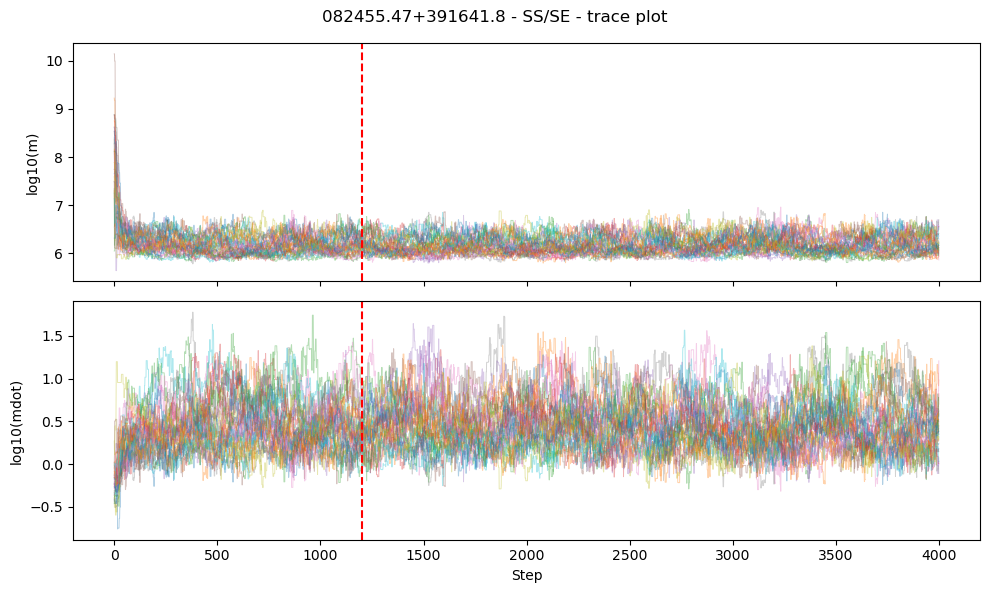

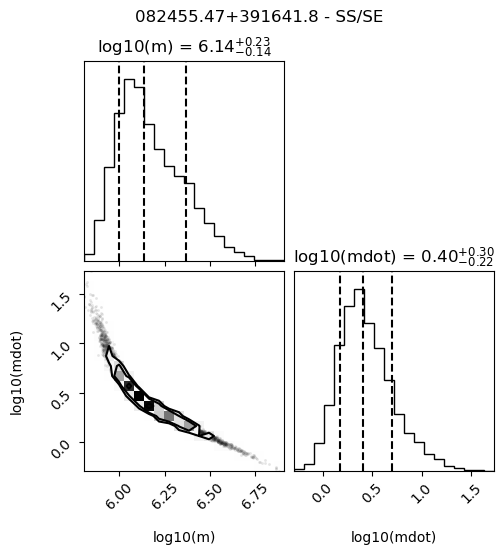

ValueError: Unexpected columns in out/mcmc_results.txt. Expected: Nome completo, Label, LogM_MC, Logmdot_MC, LogM_MC_err, Logmdot_MC_err

In [57]:
# ============================================================
# RUN COMPLETE FIT
# ============================================================

fit_results = fit_blazar_with_unified_mcmc(CFG)


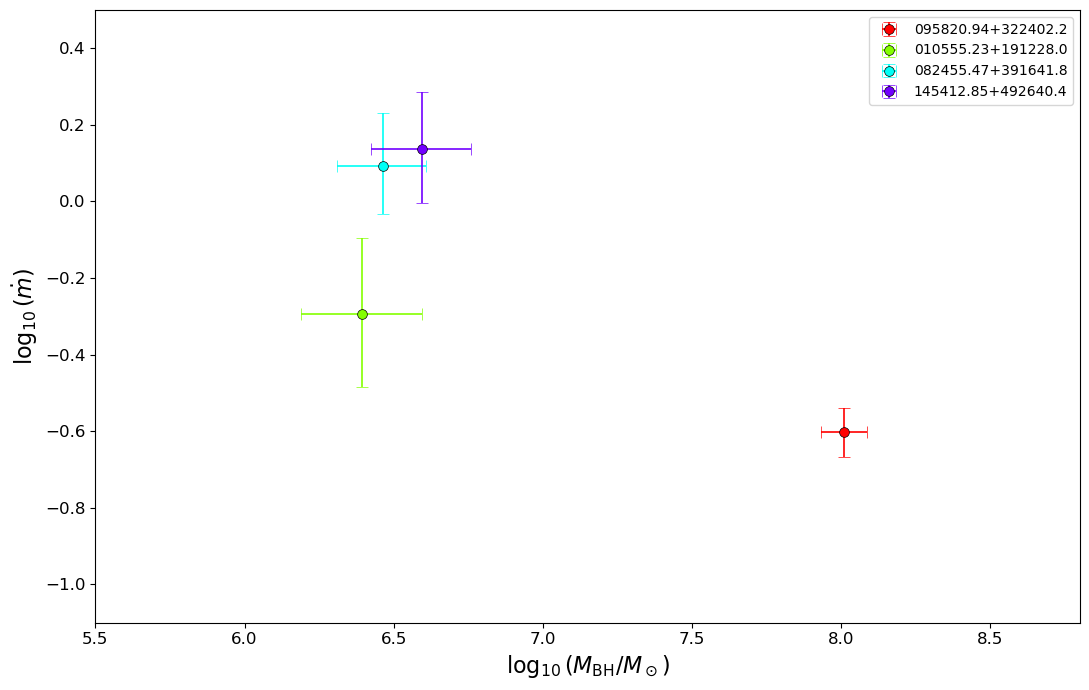

Plot saved to: out/mass_vs_accretion_rate.png


In [ ]:
# ============================================================
# MASS VS ACCRETION RATE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path

# Read the MCMC results
output_dir = Path(CFG.get("output_dir", "out"))
results_file = output_dir / "mcmc_results.txt"

df_results = pd.read_csv(results_file, sep="\t")

# Convert asymmetric errors from "+upper/-lower" to numerical values
def parse_errors(value):
    match = re.fullmatch(
        r"\s*\+?([0-9.eE+-]+)\s*/\s*-([0-9.eE+-]+)\s*",
        str(value)
    )
    if match is None:
        raise ValueError(f"Invalid uncertainty format: {value}")
    return float(match.group(2)), float(match.group(1))

x = df_results["LogM_MC"].to_numpy(dtype=float)
y = df_results["Logmdot_MC"].to_numpy(dtype=float)

x_errors = np.array([
    parse_errors(value) for value in df_results["LogM_MC_err"]
])
y_errors = np.array([
    parse_errors(value) for value in df_results["Logmdot_MC_err"]
])

labels = df_results["Label"].astype(str).to_numpy()

# Create the figure
fig, ax = plt.subplots(figsize=(11, 7))

colors = plt.cm.hsv(np.linspace(0, 1, len(df_results), endpoint=False))

for i, label in enumerate(labels):
    ax.errorbar(
        x[i], y[i],
        xerr=[[x_errors[i, 0]], [x_errors[i, 1]]],
        yerr=[[y_errors[i, 0]], [y_errors[i, 1]]],
        fmt="o",
        color=colors[i],
        ecolor=colors[i],
        markersize=7,
        capsize=4,
        elinewidth=1.2,
        markeredgecolor="black",
        markeredgewidth=0.5,
        label=label
    )

ax.set_xlim(5.5, 8.8)
ax.set_ylim(-1.1, 0.5)


# Labels and appearance
ax.set_xlabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$", fontsize=16)
ax.set_ylabel(r"$\log_{10}(\dot{m})$", fontsize=16)

ax.tick_params(axis="both", labelsize=12)
ax.legend(loc="best", fontsize=10, frameon=True)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()

# Save and display the plot
plot_path = output_dir / "mass_vs_accretion_rate.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Plot saved to: {plot_path}")
